# Kenia — BESS
Execução independente: lê somente a configuração deste módulo. As entradas externas são cenários de teste fixos, sem executar módulos de outras equipes. O fluxo elétrico no IEEE 8500 fica no notebook 04 de integração.


### Diagnóstico inicial de S1

- Vehículos eléctricos: 3,000
- Pico de demanda: 13,946 kW a las 18:00
- Línea más cargada: 108.9 %
- Líneas sobre 100 %: 37
- Tensión mínima: 0.933 pu
- Pérdidas diarias: 17.8 MWh

### Objetivo de S2

Reducir el pico, eliminar sobrecargas, recuperar la tensión a 0.95 pu
y terminar el día con el mismo SOC inicial.

## Experimento 1: BESS de 1.45 MW / 3.7 MWh

### Configuración

- Estrategia: `peak_shave`
- Potencia nominal: `1,450 kW`
- Capacidad nominal: `3,700 kWh`
- Meta de demanda: `12,500 kW`
- Barra de conexión: `m1125976`
- Fases: `ABC`
- SOC inicial: `0.70`
- SOC final: `0.70`
- Eficiencia de carga y descarga: `0.95`

### Comparación S1 versus S2

| Indicador | S1 | S2 | Cambio |
|---|---:|---:|---:|
| Pico de subestación | 13,998.58 kW | 13,801.16 kW | -197.42 kW |
| Pérdidas diarias | 17,880.25 kWh | 17,884.11 kWh | +3.86 kWh |
| Tensión mínima, reguladores activos | 0.9331 pu | 0.9346 pu | Mejora |
| Tensión mínima, taps fijos | 0.9219 pu | 0.9214 pu | Empeora ligeramente |
| Operaciones de taps | 56 | 54 | -2 |

### Interpretación

La BESS redujo el pico de la subestación en aproximadamente 197 kW,
equivalente a una reducción cercana al 1.4 %. También mejoró ligeramente
la tensión mínima con los reguladores activos y mantuvo el SOC final igual
al SOC inicial.

Sin embargo, el pico de S2 todavía alcanzó 13,801.16 kW, por encima de
la meta de 12,500 kW. La tensión mínima regulada permaneció por debajo de
0.95 pu y las pérdidas aumentaron ligeramente respecto a S1.

### Conclusión

Esta configuración produce una mejora parcial, pero todavía no cumple todos
los objetivos de S2. Se debe probar una batería de mayor potencia y
capacidad, o revisar la estrategia de despacho y la ubicación de conexión.

## Experimento 2

Configuración: BESS de 3,700 kWh y 1,450 kW, conectada en la barra
`m1125976`, con meta de 11,750 kW kW y estrategia `peak_shave`.

| Indicador | S1 | S2 |
|---|---:|---:|
| Pico de demanda | 13,998.58 kW | 12,953.36 kW |
| Carga máxima de líneas | 132.08 % | 131.07 % |
| Tensión mínima | 0.9331 pu | 0.9404 pu |
| Muestras con baja tensión | 365 | 72 |
| Muestras con sobrecarga | 221 | 66 |
| Pérdidas diarias | 17,880.25 kWh | 17,850.71 kWh |

La BESS procesó 4,357.42 kWh, realizó 0.302 ciclos equivalentes y
terminó con un SOC de 0.70, igual al valor inicial. La configuración
mejoró S1, pero todavía no alcanza una tensión mínima de 0.95 pu ni
reduce la carga máxima de las líneas por debajo del 100 %.

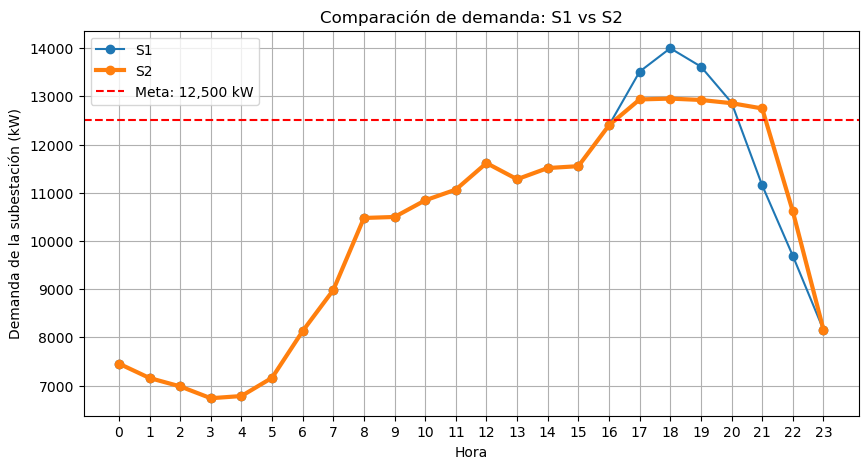

## Experimento 03: programación horaria de la BESS en l2711226
Se probó una estrategia nueva, separada del peak_shave original, para una BESS de 7,200 kWh y 2,200 kW. La simulación integrada tiene 24 pasos de una hora. La estrategia calcula el horario completo para reducir el pico de demanda, impide recargar entre las 12:00 y las 21:00 y limita la recarga a 300 kW a las 22:00 y 600 kW a las 23:00. Estos límites son hipótesis de prueba que requieren validación eléctrica.

La BESS cargó 1,516 kW a las 03:00; descargó entre las 17:00 y las 20:00, con un máximo de 953 kW a las 18:00; y volvió a cargar a las 22:00 y 23:00. El SOC pasó de 0.70 a 0.90, bajó hasta 0.581 y terminó nuevamente en 0.70.
Indicador	S1, sin BESS	S2, estrategia nueva
Pico en la subestación	13,998.6 kW	12,950.0 kW
Carga máxima de una línea	132.1 %	117.7 %
Tensión mínima	0.9331 pu	0.9401 pu
Muestras con sobrecarga	221	62
Pérdidas diarias	17,880.3 kWh	17,801.4 kWh


Interpretación. La estrategia evitó la recarga perjudicial de las 21:00 del experimento anterior, cuya carga máxima había llegado al 149.1 %. Sin embargo, la recarga concentrada a las 03:00 produjo 111.0 % en ln6351510-1. La peor sobrecarga actual es 117.7 % a las 20:00 en esa misma línea. La tensión mínima aún está por debajo de 0.95 pu. Por tanto, S2 mejoró frente a S1, pero todavía no cumple todos los objetivos del proyecto. La estrategia optimiza la demanda agregada; no optimiza directamente la carga de las líneas ni la tensión.

## Experimento 7 — BESS en `l3029502` (configuración seleccionada)

### Configuración

- Escenario: S2 = S1 + una BESS.
- Barra de conexión: `l3029502`, fases `ABC`.
- Potencia nominal: **2.200 kW**.
- Capacidad nominal: **7.200 kWh**.
- SOC inicial y final: **0,30**; límites: **0,10–0,90**.
- Eficiencia de carga y descarga: **0,95**.
- Estrategia: `trial7_schedule`, con un programa fijo de **24 intervalos de una hora**. El comando positivo descarga la batería.
- Operación principal: carga de **620 kW entre las 00:00 y las 06:00**; descarga de aproximadamente **401 kW a las 16:00** y **1.679 kW a las 18:00**.

### Resultados de la integración horaria

| Indicador | S1, sin BESS | S2, prueba 7 |
|---|---:|---:|
| Pico de potencia en la subestación | 13.998,58 kW | **12.786,15 kW** |
| Carga máxima de línea | 132,08 % | **100,12 %** |
| Muestras con sobrecarga | 221 | **3** |
| Tensión mínima, reguladores activos | 0,9331 pu | **0,9517 pu** |
| Muestras con tensión fuera de límite | 365 | **0** |
| Pérdidas diarias | 17.880,25 kWh | **17.613,01 kWh** |

La batería redujo el pico en **1.212,43 kW** y las pérdidas en **267,25 kWh** respecto a S1. Procesó **9.921,14 kWh** de energía AC, equivalentes a **0,688 ciclos**, y terminó con el mismo SOC de 0,30.

### Interpretación y límite

La prueba 7 es la mejor configuración de una sola BESS seleccionada en este estudio: reduce considerablemente el pico y las sobrecargas. Sin embargo, la carga máxima todavía llega a **100,12 %** y quedan **tres muestras con sobrecarga**, asociadas a la rama sur alrededor de las 18:00. Por tanto, **no se ha cumplido el objetivo de eliminar todas las sobrecargas**.

Con los taps de los reguladores congelados, la tensión mínima de S2 fue **0,9313 pu**. La mejora de tensión observada con los reguladores activos depende, en parte, de su actuación.

El horario de `trial7_schedule` se obtuvo para el día S1 estudiado. Es una programación fija: **no se adapta automáticamente** a otro perfil de demanda. El parámetro `target_kw` que permanece en la configuración es histórico y esta estrategia no lo utiliza.

**Fuente:** `results/ieee8500/peak_reserve_l3029502_trial7/summary.csv` y `modules/bess/S2/dispatch.csv` dentro de esa carpeta.